Shortest Distance Found: 320.53
Best Route: [2, np.int64(7), np.int64(11), np.int64(8), np.int64(13), np.int64(3), np.int64(5), np.int64(0), np.int64(12), np.int64(4), np.int64(1), np.int64(6), np.int64(10), np.int64(14), np.int64(9), 2]


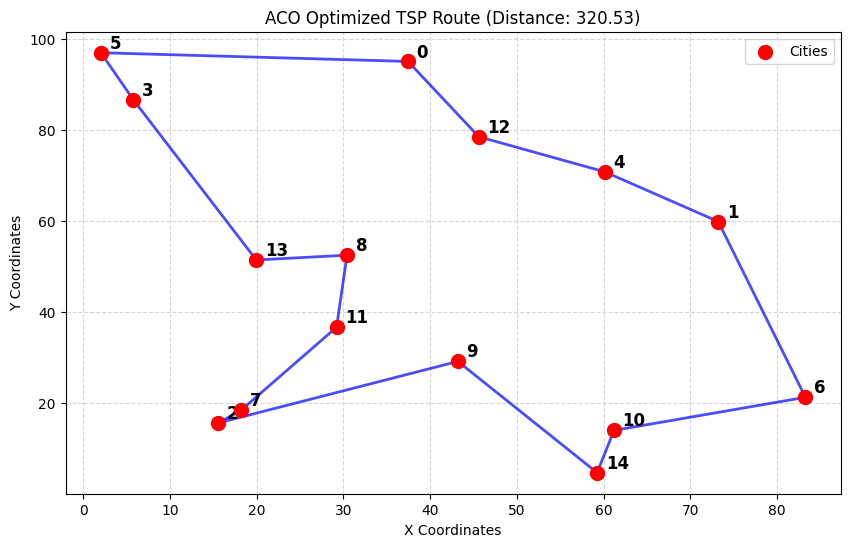

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Generate random cities
np.random.seed(42)
num_cities = 15
city_coords = np.random.rand(num_cities, 2) * 100

# Calculate distance matrix
dist_matrix = np.zeros((num_cities, num_cities))
for i in range(num_cities):
    for j in range(num_cities):
        if i != j:
            dist_matrix[i, j] = np.linalg.norm(city_coords[i] - city_coords[j])
        else:
            dist_matrix[i, j] = 1e-10  # Avoid division by zero

class ACO_TSP:
    def __init__(self, dist_matrix, num_ants=15, max_iter=100, alpha=1.0, beta=2.0, evaporation_rate=0.5, Q=100):
        self.dist_matrix = dist_matrix
        self.num_cities = dist_matrix.shape[0]
        self.num_ants = num_ants
        self.max_iter = max_iter
        self.alpha = alpha  # Pheromone importance
        self.beta = beta    # Distance heuristic importance
        self.rho = evaporation_rate
        self.Q = Q

        # Initialize pheromones
        self.pheromones = np.ones((self.num_cities, self.num_cities)) * 0.1
        self.heuristics = 1.0 / self.dist_matrix
        np.fill_diagonal(self.heuristics, 0)

        self.g_best_path = None
        self.g_best_distance = float('inf')

    def run(self):
        history = []
        for it in range(self.max_iter):
            paths = []
            distances = []

            for ant in range(self.num_ants):
                path = self.construct_path()
                dist = self.calculate_path_distance(path)
                paths.append(path)
                distances.append(dist)

                if dist < self.g_best_distance:
                    self.g_best_distance = dist
                    self.g_best_path = path

            # Evaporate pheromones
            self.pheromones *= (1.0 - self.rho)

            # Deposit pheromones
            for path, dist in zip(paths, distances):
                deposit = self.Q / dist
                for k in range(self.num_cities):
                    i, j = path[k], path[k+1]
                    self.pheromones[i, j] += deposit
                    self.pheromones[j, i] += deposit

            history.append(self.g_best_distance)
        return self.g_best_path, self.g_best_distance, history

    def construct_path(self):
        path = [np.random.randint(self.num_cities)]
        unvisited = set(range(self.num_cities))
        unvisited.remove(path[0])

        while unvisited:
            current = path[-1]
            candidates = list(unvisited)

            # Calculate transition probabilities
            p_numerator = (self.pheromones[current, candidates] ** self.alpha) * (self.heuristics[current, candidates] ** self.beta)
            probs = p_numerator / np.sum(p_numerator)

            next_city = np.random.choice(candidates, p=probs)
            path.append(next_city)
            unvisited.remove(next_city)

        path.append(path[0]) # Return to start
        return path

    def calculate_path_distance(self, path):
        return sum(self.dist_matrix[path[i], path[i+1]] for i in range(self.num_cities))

# Run TSP Optimizer
aco_tsp = ACO_TSP(dist_matrix, num_ants=20, max_iter=150)
best_route, best_dist, tsp_history = aco_tsp.run()

print(f"Shortest Distance Found: {best_dist:.2f}")
print(f"Best Route: {best_route}")

# Visualize Path
plt.figure(figsize=(10, 6))
plt.scatter(city_coords[:, 0], city_coords[:, 1], color='red', s=100, zorder=5, label='Cities')
for i, (x, y) in enumerate(city_coords):
    plt.text(x + 1, y + 1, str(i), fontsize=12, fontweight='bold')

# Plot paths
for i in range(len(best_route) - 1):
    pt1 = city_coords[best_route[i]]
    pt2 = city_coords[best_route[i+1]]
    plt.plot([pt1[0], pt2[0]], [pt1[1], pt2[1]], color='blue', alpha=0.7, linewidth=2)

plt.title(f"ACO Optimized TSP Route (Distance: {best_dist:.2f})")
plt.xlabel("X Coordinates")
plt.ylabel("Y Coordinates")
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()